In [1]:
import os
import glob
import numpy as np
import scipy.io
from scipy.stats import kurtosis, skew

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix


In [2]:
def extract_features(signal, window_size=1024):
    num_windows = len(signal) // window_size
    features = []

    for i in range(num_windows):
        window = signal[i*window_size : (i+1)*window_size]

        mean_val = np.mean(window)
        std_val = np.std(window)
        rms_val = np.sqrt(np.mean(window**2))
        peak_val = np.max(np.abs(window))
        p2p_val = np.ptp(window)
        kurt_val = kurtosis(window)
        skew_val = skew(window)
        crest_factor = peak_val / rms_val if rms_val != 0 else 0

        features.append([
            mean_val, std_val, rms_val, peak_val,
            p2p_val, kurt_val, skew_val, crest_factor
        ])

    return np.array(features)


In [3]:
def load_data(root_dir, sub_folder, label):
    all_features = []

    path = os.path.join(root_dir, sub_folder, "**", "*.mat")
    files = glob.glob(path, recursive=True)

    print(f"Found {len(files)} files in '{sub_folder}'")

    for file_path in files:
        try:
            mat = scipy.io.loadmat(file_path)

            de_key = None
            for k in mat.keys():
                if k.endswith("DE_time"):
                    de_key = k
                    break

            if de_key:
                signal = mat[de_key].flatten()
                feats = extract_features(signal)
                all_features.append(feats)

        except Exception as e:
            print("Error:", e)

    if not all_features:
        return np.array([]), np.array([])

    X = np.vstack(all_features)
    y = np.full(X.shape[0], label)

    return X, y


In [4]:
dataset_path = r"g:\Projects\Predicitive_Maintanace\CWRU-dataset"

X_normal, y_normal = load_data(dataset_path, "Normal", label=0)
X_ball, y_ball = load_data(dataset_path, r"12k_Drive_End_Bearing_Fault_Data\B", label=1)
X_inner, y_inner = load_data(dataset_path, r"12k_Drive_End_Bearing_Fault_Data\IR", label=2)
X_outer, y_outer = load_data(dataset_path, r"12k_Drive_End_Bearing_Fault_Data\OR", label=3)

# combine
X = np.vstack([X_normal, X_ball, X_inner, X_outer])
y = np.concatenate([y_normal, y_ball, y_inner, y_outer])

print("Total samples:", X.shape[0])
print("Features per sample:", X.shape[1])


Found 4 files in 'Normal'
Found 16 files in '12k_Drive_End_Bearing_Fault_Data\B'
Found 16 files in '12k_Drive_End_Bearing_Fault_Data\IR'
Found 28 files in '12k_Drive_End_Bearing_Fault_Data\OR'
Total samples: 8767
Features per sample: 8


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [6]:
clf = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    max_depth=None,
    n_jobs=-1
)

clf.fit(X_train_scaled, y_train)


RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)

In [7]:
y_pred = clf.predict(X_test_scaled)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Normal", "Ball Fault", "Inner Race Fault", "Outer Race Fault"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))



Classification Report:
                  precision    recall  f1-score   support

          Normal       1.00      1.00      1.00       331
      Ball Fault       0.98      0.98      0.98       379
Inner Race Fault       0.96      0.98      0.97       379
Outer Race Fault       0.98      0.97      0.98       665

        accuracy                           0.98      1754
       macro avg       0.98      0.98      0.98      1754
    weighted avg       0.98      0.98      0.98      1754

Confusion Matrix:
[[331   0   0   0]
 [  0 370   4   5]
 [  0   0 373   6]
 [  0   8  10 647]]


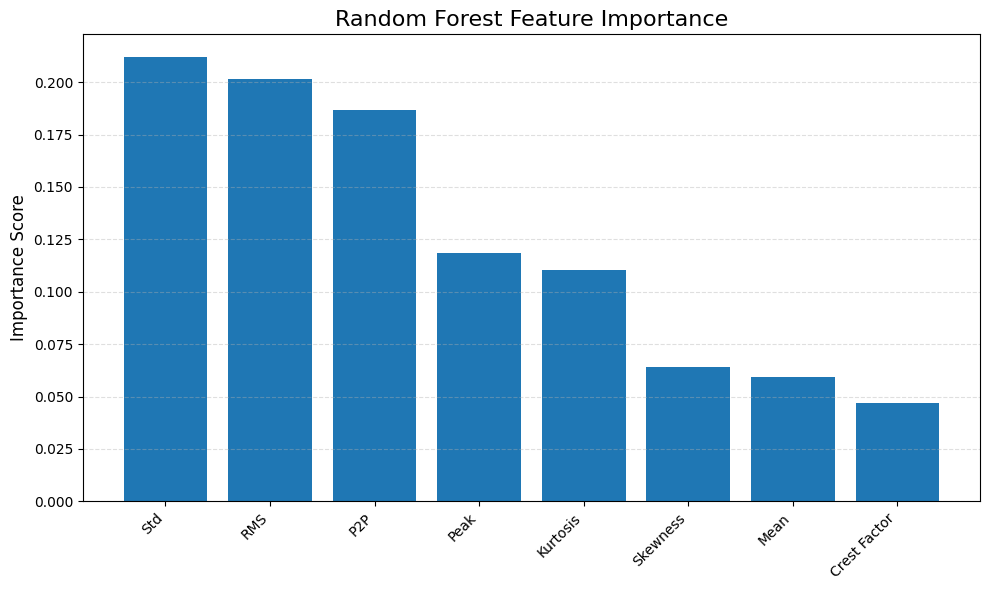

Std: 0.2122
RMS: 0.2016
P2P: 0.1867
Peak: 0.1186
Kurtosis: 0.1102
Skewness: 0.0643
Mean: 0.0595
Crest Factor: 0.0468


In [8]:
import matplotlib.pyplot as plt
import numpy as np

feature_names = [
    "Mean", "Std", "RMS", "Peak", "P2P",
    "Kurtosis", "Skewness", "Crest Factor"
]

importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]  # sort from most important to least

plt.figure(figsize=(10, 6))
plt.title("Random Forest Feature Importance", fontsize=16)
plt.bar(range(len(importances)), importances[indices], align='center')
plt.xticks(range(len(importances)), [feature_names[i] for i in indices], rotation=45, ha="right")
plt.ylabel("Importance Score", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Print values for clarity
for idx in indices:
    print(f"{feature_names[idx]}: {importances[idx]:.4f}")


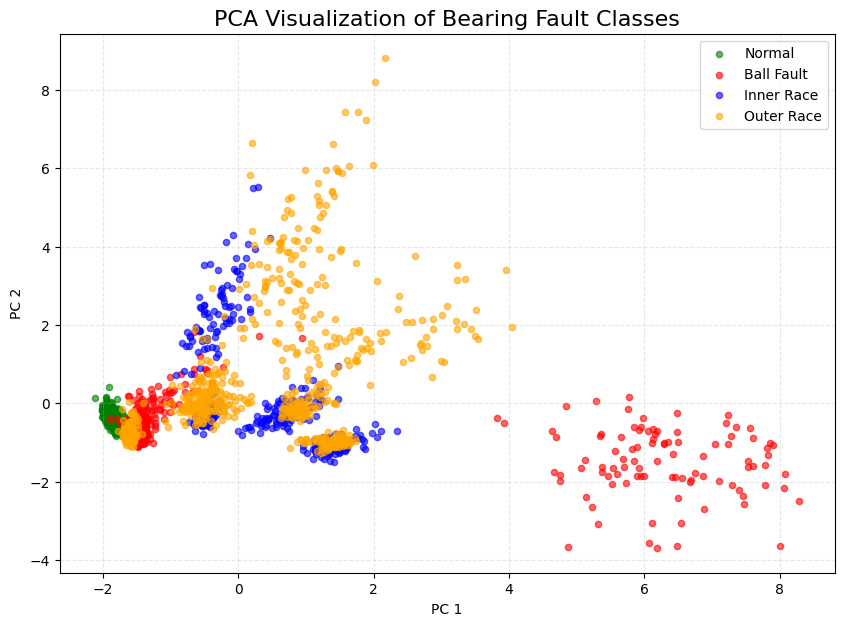

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Run PCA on your *scaled* data
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_test_scaled)

plt.figure(figsize=(10, 7))
for label, name, color in [
    (0, "Normal", "green"),
    (1, "Ball Fault", "red"),
    (2, "Inner Race", "blue"),
    (3, "Outer Race", "orange")
]:
    plt.scatter(
        X_pca[y_test == label, 0],
        X_pca[y_test == label, 1],
        label=name,
        alpha=0.6,
        s=20,
        color=color
    )

plt.title("PCA Visualization of Bearing Fault Classes", fontsize=16)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.show()


C:\Users\smsah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\manifold\_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


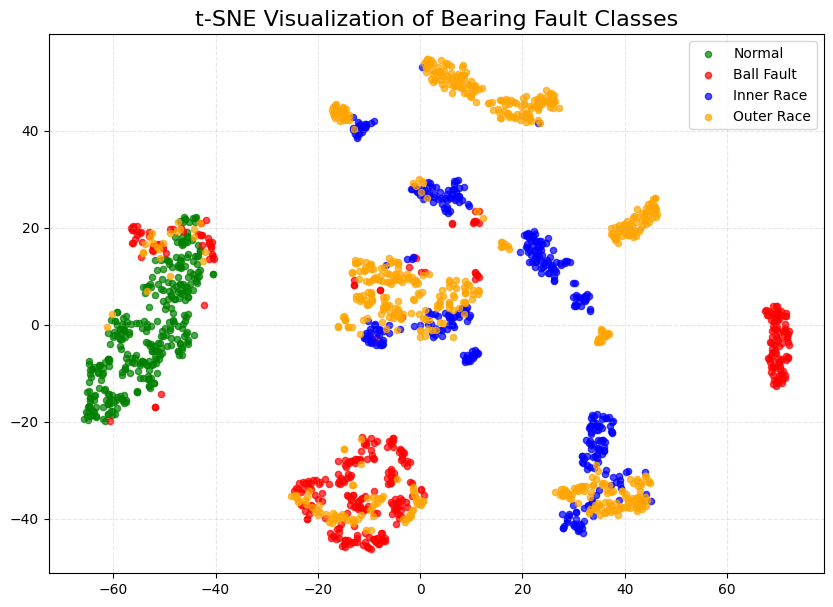

In [12]:
from sklearn.manifold import TSNE

# Reduce to 4 components before t-SNE
pca_4 = PCA(n_components=4)
X_reduced = pca_4.fit_transform(X_test_scaled)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate=200,
    n_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X_reduced)

plt.figure(figsize=(10, 7))
for label, name, color in [
    (0, "Normal", "green"),
    (1, "Ball Fault", "red"),
    (2, "Inner Race", "blue"),
    (3, "Outer Race", "orange")
]:
    plt.scatter(
        X_tsne[y_test == label, 0],
        X_tsne[y_test == label, 1],
        label=name,
        alpha=0.7,
        s=20,
        color=color
    )

plt.title("t-SNE Visualization of Bearing Fault Classes", fontsize=16)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.show()

